# Chapitre 12 - Cours 2 : dégrouper la base de données

Le cours 1 a montré qu'une organisation qui dérive ses données d'un journal fait, à
grande échelle, ce qu'une base de données fait en interne quand elle tient ses index à
jour. Ce notebook prend l'analogie au sérieux : que se passe-t-il si l'on **sépare les
composants** d'une base (journal, index, vues matérialisées, code applicatif) et qu'on
les recompose avec des flux ? Il couvre les sections *Unbundling Databases* (*Composing
Data Storage Technologies*, y compris *What's missing?*) et *Designing Applications
Around Dataflow*.

**Plan.**

1. Bases de données, Unix et dégroupage.
2. Créer un index, c'est dériver une vue.
3. La méta-base de données de toute l'organisation.
4. Faire fonctionner le dégroupage : le couplage lâche.
5. Dégroupé ou intégré ?
6. Le code applicatif comme fonction de dérivation : le modèle du tableur.
7. Séparer le code et l'état, et s'abonner aux changements.
8. Processeurs de flux et services.

In [1]:
import math
import random
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import dataflow as dfl
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. Bases de données, Unix et dégroupage (section *Unbundling Databases*)

Vu de haut, une base de données, un moteur de traitement par lots ou de flux et un
système d'exploitation font la même chose : ils **stockent** des données et permettent
de les **traiter et interroger**. La base range des enregistrements d'un modèle de
données (lignes, documents, sommets), le système de fichiers range des fichiers ; ce
sont deux systèmes de gestion de l'information (avec de grosses différences pratiques :
dix millions de petits fichiers dans un répertoire gênent la plupart des systèmes de
fichiers, dix millions de petites lignes dans une table sont banals).

Les deux traditions ont pourtant des philosophies opposées, nées au même moment (Unix
et le modèle relationnel datent tous deux du début des années 1970) :

| | Unix | bases relationnelles |
|---|---|---|
| abstraction | mince couche logique au-dessus du matériel | haut niveau : cache structures disque, concurrence, reprise |
| briques | fichiers = suites d'octets, tubes (pipes) | SQL, transactions |
| « simple » parce que... | peu de choses entre vous et le matériel | une requête déclarative courte mobilise optimiseur, index, jointures, réplication |
| composition | petits outils assemblés par le shell | un seul système intégré |

Le mouvement NoSQL peut se lire comme l'application de l'esprit Unix (abstractions de
bas niveau) au stockage transactionnel distribué. Le livre tente de **réconcilier** les
deux : garder les abstractions de haut niveau des bases, mais les construire en
composant des briques spécialisées, comme le shell compose des outils.

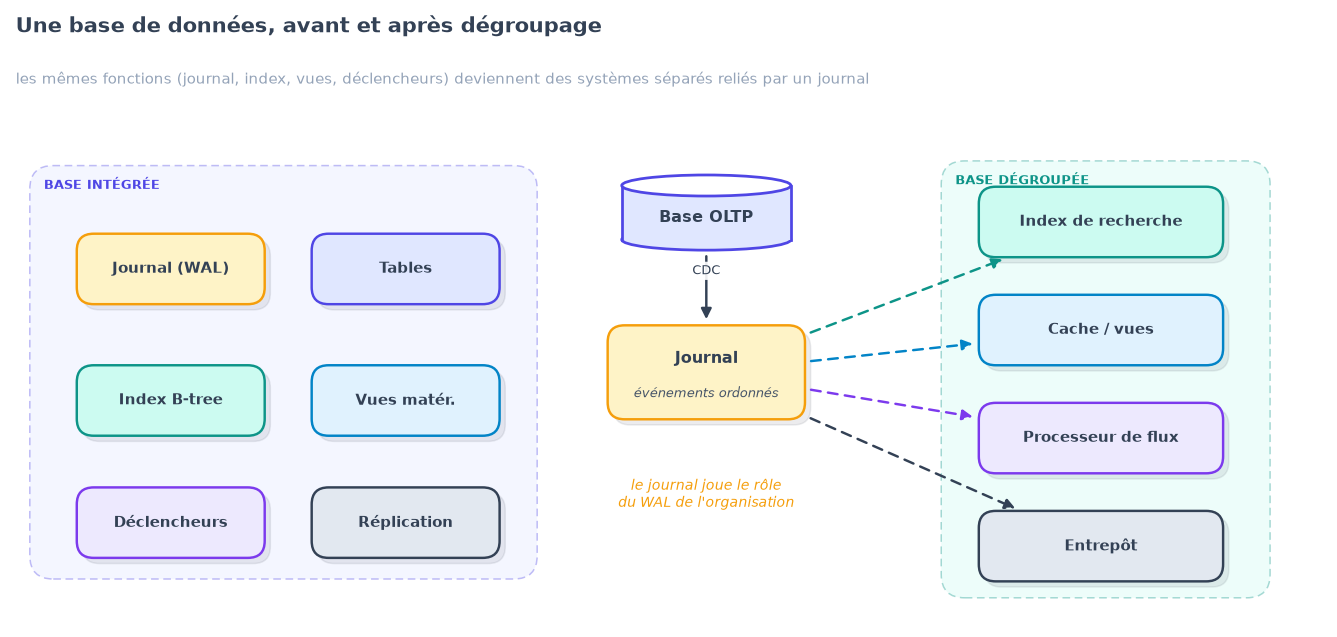

In [2]:
d = Diagram(14, 5.6, title="Une base de données, avant et après dégroupage",
            subtitle="les mêmes fonctions (journal, index, vues, déclencheurs) deviennent des systèmes séparés reliés par un journal")
d.group(0.2, 0.5, 5.6, 4.9, "base intégrée", color=INDIGO)
inner = [("wal", "Journal (WAL)", 1.7, 3.8, AMBER), ("tbl", "Tables", 4.2, 3.8, INDIGO),
         ("ix", "Index B-tree", 1.7, 2.4, TEAL), ("mv", "Vues matér.", 4.2, 2.4, SKY),
         ("trg", "Déclencheurs", 1.7, 1.1, VIOLET), ("rep", "Réplication", 4.2, 1.1, SLATE)]
for name, txt, x, y, c in inner:
    d.box(name, x, y, txt, color=c, w=2.0, h=0.75, fontsize=9.5)
d.box("log", 7.4, 2.7, "Journal", sub="événements ordonnés", color=AMBER, w=2.1, h=1.0)
outer = [("es", "Index de recherche", 11.6, 4.3, TEAL), ("cache", "Cache / vues", 11.6, 3.15, SKY),
         ("sp", "Processeur de flux", 11.6, 2.0, VIOLET), ("dwh", "Entrepôt", 11.6, 0.85, SLATE)]
d.group(9.9, 0.3, 13.4, 4.95, "base dégroupée", color=TEAL)
for name, txt, x, y, c in outer:
    d.box(name, x, y, txt, color=c, w=2.6, h=0.75, fontsize=9.5)
    d.arrow("log", name, style="dashed", color=c)
d.box("db", 7.4, 4.4, "Base OLTP", color=INDIGO, kind="db", w=1.8, h=0.8)
d.arrow("db", "log", "CDC")
d.note(7.4, 1.4, "le journal joue le rôle\ndu WAL de l'organisation", color=AMBER)
d.show()

> **À retenir.** Unix compose de petits outils de bas niveau ; les bases offrent une
> abstraction de haut niveau intégrée. Dégrouper la base, c'est chercher le meilleur des
> deux : des fonctions de base de données (index, vues, déclencheurs) fournies par des
> systèmes séparés, assemblés par un journal.